# TripWorld EDA, Cleaning & Reporting

Explore the raw data, audit data quality, and visualize cleaning results.

Cleaning logic is in `ml/data_pipeline.py`. Summaries are saved to
`reports/data_cleaning_summary.json` and charts to `reports/figures/`.

Cleaning is optional and disabled by default.


## 1. Setup

Run from the repository root or `notebooks/`. Install `ml/requirements.txt`, Matplotlib, and Seaborn.

Place core data in `data/tripworld/`. Reviews are not required. In Colab, clone or mount the project first.


In [1]:
import os
import sys
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "ml" / "data_pipeline.py").is_file():
    raise FileNotFoundError("Set the working directory to the repository root first.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from ml.config import DATA_RAW_DIR, REPORTS_DIR
required = ["pois.parquet", "travel_behaviors.parquet", "region_labels.parquet",
            "metadata/metadata_all.parquet"]
missing = [name for name in required if not (DATA_RAW_DIR / name).is_file()]
if missing:
    raise FileNotFoundError(f"Missing core inputs under {DATA_RAW_DIR}: {missing}")
(REPORTS_DIR / "figures").mkdir(parents=True, exist_ok=True)
print("Project:", PROJECT_ROOT)


Project: /Users/liliya/sjsu/1_term/Recommender Systems/cmpe-256-final-project


## 2. Explore raw data

Review dataset size, geography, trip lengths, and categories. Category lift uses sampled data.


In [2]:
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid", palette="deep")
con = duckdb.connect()
con.execute('''
    CREATE VIEW travel AS SELECT * FROM 'data/tripworld/travel_behaviors.parquet';
    CREATE VIEW pois AS SELECT * FROM 'data/tripworld/pois.parquet';
    CREATE VIEW meta AS SELECT * FROM 'data/tripworld/metadata/metadata_all.parquet';
    CREATE VIEW regions AS SELECT * FROM 'data/tripworld/region_labels.parquet';
''')

# Headline summary table
summary = con.sql('''
    SELECT
        (SELECT COUNT(*) FROM travel) AS cross_city_trips,
        (SELECT COUNT(DISTINCT user_id) FROM travel) AS unique_travelers,
        (SELECT COUNT(*) FROM pois) AS total_pois,
        (SELECT COUNT(*) FROM regions) AS metro_regions,
        (SELECT ROUND(100.0 * AVG(CAST(has_google_metadata AS INT)), 2) FROM pois) AS pct_google_meta,
        (SELECT ROUND(100.0 * AVG(CAST(has_reviews AS INT)), 2) FROM pois) AS pct_with_reviews
''').df()
display(summary)
        

,cross_city_trips,unique_travelers,total_pois,metro_regions,pct_google_meta,pct_with_reviews
0,518567,148402,687173,1173,82.48,76.33


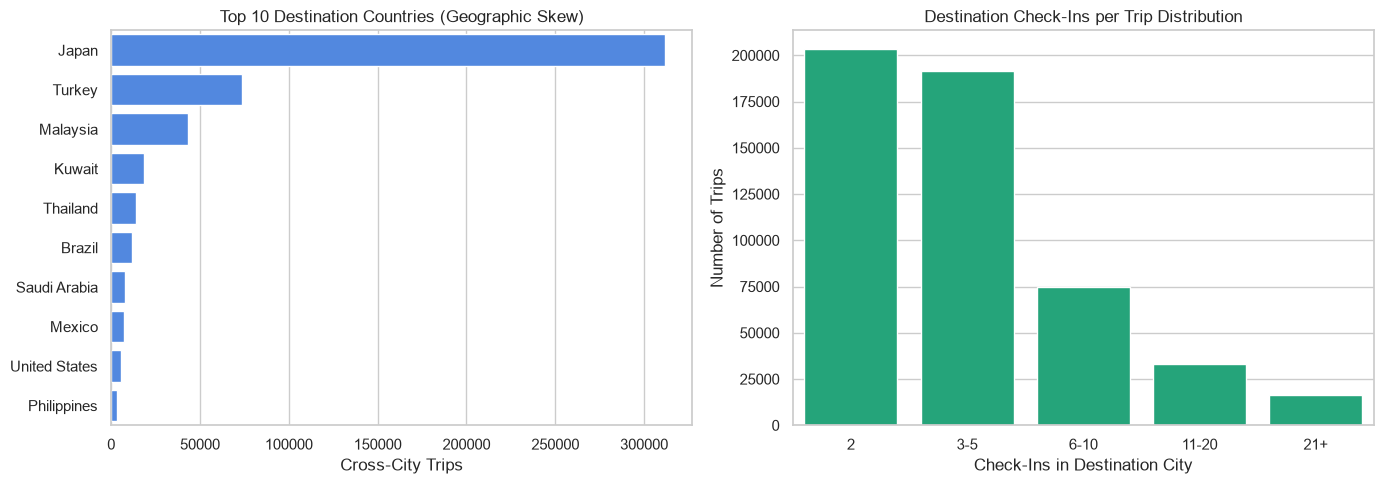

In [3]:
# Figure 1: Top Countries by Cross-City Trips & Trip Length Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

top_countries = con.sql('''
    SELECT r.country_name, COUNT(*) AS trips
    FROM travel t
    JOIN regions r ON t.r_o = r.region_id
    GROUP BY 1 ORDER BY trips DESC LIMIT 10
''').df()

sns.barplot(data=top_countries, y="country_name", x="trips", ax=axes[0], color="#3b82f6")
axes[0].set_title("Top 10 Destination Countries (Geographic Skew)")
axes[0].set_xlabel("Cross-City Trips")
axes[0].set_ylabel("")

trip_lens = con.sql('''
    SELECT
        CASE
            WHEN n_travel_ci = 2 THEN '2'
            WHEN n_travel_ci BETWEEN 3 AND 5 THEN '3-5'
            WHEN n_travel_ci BETWEEN 6 AND 10 THEN '6-10'
            WHEN n_travel_ci BETWEEN 11 AND 20 THEN '11-20'
            ELSE '21+'
        END AS bucket,
        COUNT(*) AS trips,
        MIN(n_travel_ci) AS sort_k
    FROM travel GROUP BY 1 ORDER BY sort_k
''').df()

sns.barplot(data=trip_lens, x="bucket", y="trips", ax=axes[1], color="#10b981")
axes[1].set_title("Destination Check-Ins per Trip Distribution")
axes[1].set_xlabel("Check-Ins in Destination City")
axes[1].set_ylabel("Number of Trips")

plt.tight_layout()
plt.savefig("reports/figures/01_kdd_geography_and_trip_lengths.png", dpi=150)
plt.show()
        

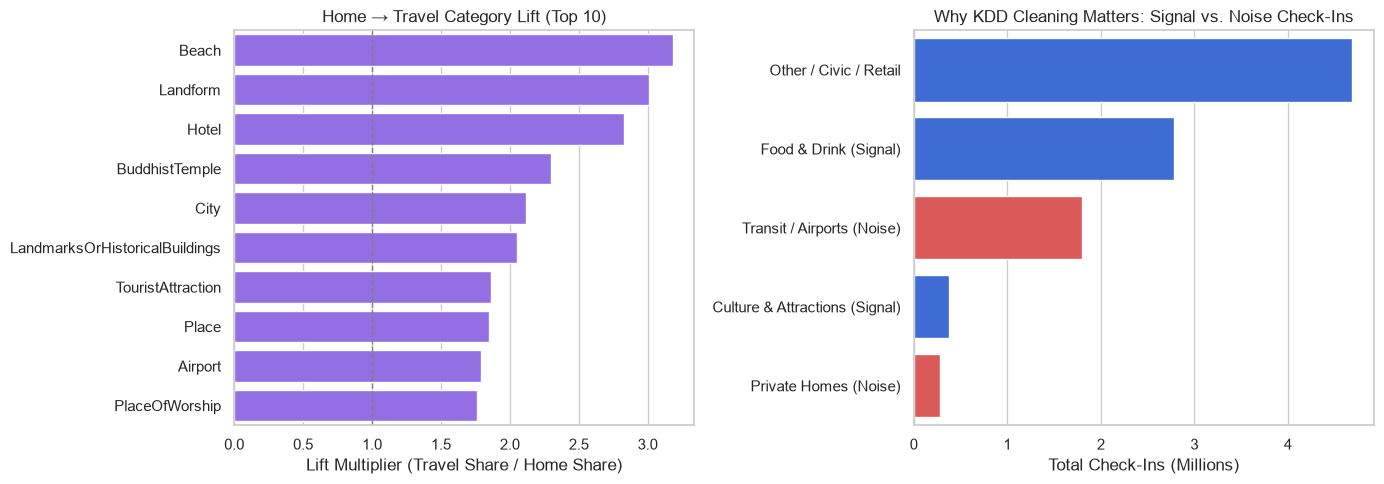

In [4]:
# Figure 2: Home -> Travel Category Lift (What Surges on Trips) + Signal vs Noise Check-Ins
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

lift_df = con.sql('''
    WITH h AS (
        SELECT u.venue_schema AS s, COUNT(*) AS cnt
        FROM (SELECT c_h FROM travel USING SAMPLE 50000 ROWS), UNNEST(c_h) AS _(u)
        WHERE u.venue_schema IS NOT NULL GROUP BY 1
    ),
    o AS (
        SELECT u.venue_schema AS s, COUNT(*) AS cnt
        FROM (SELECT c_o FROM travel USING SAMPLE 50000 ROWS), UNNEST(c_o) AS _(u)
        WHERE u.venue_schema IS NOT NULL GROUP BY 1
    ),
    tot AS (SELECT (SELECT SUM(cnt) FROM h) AS ht, (SELECT SUM(cnt) FROM o) AS ot)
    SELECT REPLACE(o.s, 'schema:', '') AS category,
           ROUND((o.cnt / tot.ot) / NULLIF(COALESCE(h.cnt, 1) / tot.ht, 0), 2) AS travel_lift
    FROM o LEFT JOIN h ON o.s = h.s CROSS JOIN tot
    WHERE o.cnt >= 800
    ORDER BY travel_lift DESC LIMIT 10
''').df()

sns.barplot(data=lift_df, y="category", x="travel_lift", ax=axes[0], color="#8b5cf6")
axes[0].axvline(1.0, color="gray", linestyle="--", linewidth=1)
axes[0].set_title("Home → Travel Category Lift (Top 10)")
axes[0].set_xlabel("Lift Multiplier (Travel Share / Home Share)")
axes[0].set_ylabel("")

noise_df = con.sql('''
    SELECT
        CASE
            WHEN venue_schema IN ('schema:TrainStation','schema:SubwayStation','schema:BusStation','schema:Airport') THEN 'Transit / Airports (Noise)'
            WHEN venue_schema IN ('schema:House','schema:ApartmentComplex','schema:Residence') THEN 'Private Homes (Noise)'
            WHEN venue_schema IN ('schema:Restaurant','schema:FoodEstablishment','schema:CafeOrCoffeeShop','schema:BarOrPub') THEN 'Food & Drink (Signal)'
            WHEN venue_schema IN ('schema:Museum','schema:ArtGallery','schema:LandmarksOrHistoricalBuildings','schema:TouristAttraction','schema:Park','schema:Beach','schema:BuddhistTemple') THEN 'Culture & Attractions (Signal)'
            ELSE 'Other / Civic / Retail'
        END AS bucket,
        SUM(n_checkins) / 1e6 AS checkins_millions
    FROM pois GROUP BY 1 ORDER BY checkins_millions DESC
''').df()

palette = ["#ef4444" if "Noise" in b else "#2563eb" for b in noise_df["bucket"]]
sns.barplot(data=noise_df, y="bucket", x="checkins_millions", hue="bucket", legend=False, ax=axes[1], palette=palette)
axes[1].set_title("Why KDD Cleaning Matters: Signal vs. Noise Check-Ins")
axes[1].set_xlabel("Total Check-Ins (Millions)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig("reports/figures/02_kdd_travel_lift_and_noise.png", dpi=150)
plt.show()
        

## 3. Audit inputs

Check missing values, duplicate keys, unmatched IDs, and visit timestamps. Records stay unchanged.

Home histories repeat across trip records. Missing region labels need investigation, not automatic removal.

Existing cleaning summaries are preserved; this audit is available in `raw_audit`.


In [5]:
import json
from ml.config import REPORTS_DIR
from ml.data_pipeline import audit_raw_inputs, write_cleaning_summary

with duckdb.connect() as audit_con:
    raw_audit = audit_raw_inputs(audit_con)
print(json.dumps(raw_audit, indent=2))

# Preserve an existing pipeline report; audit-only runs must not erase cleaning evidence.
summary_path = REPORTS_DIR / "data_cleaning_summary.json"
if not summary_path.exists():
    write_cleaning_summary(raw_audit)
    print("Saved audit-only summary:", summary_path)
else:
    print("Existing summary retained. Current audit is in raw_audit; check report date/status below.")


{
  "tables": {
    "pois": {
      "rows": 687173,
      "null_counts": {
        "fsq_place_id": 0,
        "locality": 0,
        "venue_category": 0,
        "venue_schema": 0,
        "n_checkins": 0,
        "n_users_visited": 0,
        "google_cid": 120375,
        "google_name": 120375,
        "google_full_address": 120681,
        "google_address": 120765,
        "google_website": 312719,
        "google_rating": 161600,
        "google_num_reviews": 161806,
        "google_categories": 124945,
        "google_place_id": 120375,
        "google_gmaps_url": 120375,
        "google_meta_source": 0,
        "has_google_metadata": 0,
        "n_reviews": 0,
        "n_reviews_with_text": 0,
        "review_source": 162643,
        "has_reviews": 0
      },
      "missing_ids": {
        "fsq_place_id": 0,
        "locality": 0
      },
      "duplicate_key_rows": 0
    },
    "metadata": {
      "rows": 687173,
      "null_counts": {
        "fsq_place_id": 0,
        "benchmar

### Missing region labels

Which regions lack labels? Are their POIs used in trips? Can metadata provide display names?

These checks do not change data. Metadata names are suggestions to review, not verified region mappings.


In [6]:
con.execute("""
    CREATE OR REPLACE TEMP VIEW unmatched_region_pois AS
    SELECT p.fsq_place_id AS poi_id, p.locality AS region_id,
           m.fsq_locality, m.benchmark_locality, m.fsq_country,
           m.fsq_latitude AS lat, m.fsq_longitude AS lon
    FROM pois p
    LEFT JOIN meta m ON p.fsq_place_id = m.fsq_place_id
    WHERE NULLIF(TRIM(p.locality), '') IS NOT NULL
      AND NOT EXISTS (SELECT 1 FROM regions r WHERE r.region_id = p.locality)
""")
region_overview = con.sql("""
    SELECT COUNT(*) AS affected_pois, COUNT(DISTINCT region_id) AS unmatched_regions,
           COUNT(*) FILTER (WHERE NULLIF(TRIM(fsq_locality), '') IS NOT NULL) AS with_fsq_locality,
           COUNT(*) FILTER (WHERE NULLIF(TRIM(fsq_country), '') IS NOT NULL) AS with_country,
           COUNT(*) FILTER (WHERE lat IS NOT NULL AND lon IS NOT NULL) AS with_coordinates
    FROM unmatched_region_pois
""").df()
display(region_overview)

region_counts = con.sql("""
    SELECT region_id, COUNT(*) AS poi_count
    FROM unmatched_region_pois GROUP BY region_id ORDER BY poi_count DESC, region_id
""").df()
print("Largest unmatched regions (up to 30):")
display(region_counts.head(30))


,affected_pois,unmatched_regions,with_fsq_locality,with_country,with_coordinates
0,13755,87,12812,13752,13755


Largest unmatched regions (up to 30):


,region_id,poi_count
0,Q48344,550
1,Q385327,489
2,Q3616,429
3,Q21579751,412
4,Q31467408,396
5,Q7259868,300
6,Q986261,247
7,Q975,234
8,Q39261863,230
9,Q181056,223


In [7]:
# Source-record counts: home histories can repeat across destination records.
region_trip_impact = con.sql("""
    WITH records AS (
        SELECT ROW_NUMBER() OVER () AS record_id, user_id, r_h, r_o, c_h, c_o FROM travel
    ), affected_visits AS (
        SELECT 'Home history' AS visit_source, t.record_id, t.user_id, u.venue_id AS poi_id
        FROM records t, UNNEST(t.c_h) AS visits(u)
        WHERE EXISTS (SELECT 1 FROM unmatched_region_pois p WHERE p.poi_id = u.venue_id)
        UNION ALL
        SELECT 'Destination', t.record_id, t.user_id, u.venue_id AS poi_id
        FROM records t, UNNEST(t.c_o) AS visits(u)
        WHERE EXISTS (SELECT 1 FROM unmatched_region_pois p WHERE p.poi_id = u.venue_id)
    ), sources(visit_source) AS (VALUES ('Home history'), ('Destination'))
    SELECT s.visit_source, COUNT(v.poi_id) AS source_visit_rows,
           COUNT(DISTINCT v.poi_id) AS distinct_pois,
           COUNT(DISTINCT v.record_id) AS affected_trip_records,
           COUNT(DISTINCT v.user_id) AS affected_users
    FROM sources s LEFT JOIN affected_visits v USING (visit_source)
    GROUP BY s.visit_source ORDER BY s.visit_source
""").df()
display(region_trip_impact)

trip_region_impact = con.sql("""
    SELECT
        COUNT(*) FILTER (WHERE r_h IN (SELECT region_id FROM unmatched_region_pois)) AS home_region_records,
        COUNT(*) FILTER (WHERE r_o IN (SELECT region_id FROM unmatched_region_pois)) AS destination_region_records
    FROM travel
""").df()
display(trip_region_impact)


,visit_source,source_visit_rows,distinct_pois,affected_trip_records,affected_users
0,Destination,0,0,0,0
1,Home history,0,0,0,0


,home_region_records,destination_region_records
0,0,0


In [8]:
# Multiple names may refer to neighborhoods or municipalities; do not choose one automatically.
region_metadata = con.sql("""
    SELECT region_id, COUNT(*) AS poi_count,
           COUNT(DISTINCT NULLIF(TRIM(fsq_locality), '')) AS locality_variants,
           LIST(DISTINCT NULLIF(TRIM(fsq_locality), '') ORDER BY NULLIF(TRIM(fsq_locality), ''))
               FILTER (WHERE NULLIF(TRIM(fsq_locality), '') IS NOT NULL) AS locality_candidates,
           LIST(DISTINCT NULLIF(TRIM(benchmark_locality), '') ORDER BY NULLIF(TRIM(benchmark_locality), ''))
               FILTER (WHERE NULLIF(TRIM(benchmark_locality), '') IS NOT NULL) AS benchmark_candidates,
           LIST(DISTINCT NULLIF(TRIM(fsq_country), '') ORDER BY NULLIF(TRIM(fsq_country), ''))
               FILTER (WHERE NULLIF(TRIM(fsq_country), '') IS NOT NULL) AS country_codes
    FROM unmatched_region_pois GROUP BY region_id ORDER BY poi_count DESC, region_id
""").df()
print("Metadata candidates for the largest regions (up to 30):")
with pd.option_context('display.max_colwidth', 100):
    display(region_metadata.head(30))
print("Full results are available in region_counts and region_metadata.")


Metadata candidates for the largest regions (up to 30):


,region_id,poi_count,locality_variants,locality_candidates,benchmark_candidates,country_codes
0,Q48344,550,11,"[Camaragibe, Camaragibe, PE, Cavaleiro, Cidade Universitária - Recife, Olinda, Pernanbuco, RECIF...",[Q48344],[BR]
1,Q385327,489,8,"[Jarinu, Santo Ângelo, Sao Borja, Sao Borja, RS, Sao Borja, São Borja, RS, São Borja, São Borja,...",[Q385327],[BR]
2,Q3616,429,9,"[Lavasan, Tehran, Tehran, Iran, Tehrān, shahrokhi, tehran, تهران, شمشک بالا, لواسان]",[Q3616],[IR]
3,Q21579751,412,5,"[Minsk, Мiнск, Минск, Минск, Республика Беларусь, Мінск]",[Q21579751],[BY]
4,Q31467408,396,11,"[Antwerp, Antwerpen, Antwerpen Ll., Antwerpen, Antwerp, Anvers, Berchem, Borgerhout, Merksem, Pr...",[Q31467408],[BE]
5,Q7259868,300,11,"[Karen, Nairobi, Kenya, Kilimani, Nairobi, Ongata Rongai, Rongai Town, South C, Nairobi, Upper H...",[Q7259868],[KE]
6,Q986261,247,6,"[NATAL, Natal, Natal - Rn, Natal, RN, Parnamirim, Parnamirim, Rio Grande Do Norte]",[Q986261],[BR]
7,Q975,234,1,[San Antonio],[Q975],[US]
8,Q39261863,230,3,"[Yakutsk, Якутск, город Якутск]",[Q39261863],[RU]
9,Q181056,223,8,"[Boa Vista, Boa Vista, Boa Vista - RR, Boa Vista, RR, Mucajai, Mucajaí, Rorainópolis, boa vista]",[Q181056],[BR]


Full results are available in region_counts and region_metadata.


**Findings:** 13,755 POIs across 87 regions lack labels. None appear in the supplied home or destination visits, and none of these regions are trip origins or destinations.

Locality text exists for 12,812 POIs and country codes for 13,752. Names vary within regions, so they are not safe automatic replacements.

**Recommendation:** keep these catalog POIs and the existing region-ID fallback. No removal is needed for observed trip labels or histories. Missing names may still affect catalog browsing or future serving.


### Coordinates, ratings, and counts

Count missing and invalid values separately. Coordinates must be finite and within latitude/longitude bounds; ratings are checked against 1–5. Counts must be nonnegative.

The tables below only inspect data. Missing ratings are not a reason to remove a POI. Examples show up to three records per check.


In [3]:
con.execute("""
    CREATE OR REPLACE TEMP VIEW poi_numeric_audit AS
    SELECT p.fsq_place_id AS poi_id, p.locality AS region_id,
           COALESCE(NULLIF(p.google_name, ''), m.fsq_name, p.fsq_place_id) AS name,
           m.fsq_latitude AS lat, m.fsq_longitude AS lon,
           p.google_rating, p.google_num_reviews, p.n_checkins,
           p.n_users_visited, p.n_reviews, p.n_reviews_with_text
    FROM pois p LEFT JOIN meta m ON p.fsq_place_id = m.fsq_place_id
""")

numeric_checks = []
for column, lower, upper in [("lat", -90, 90), ("lon", -180, 180), ("google_rating", 1, 5)]:
    numeric_checks.extend([
        (column, "Missing", f"{column} IS NULL"),
        (column, "Non-finite", f"{column} IS NOT NULL AND NOT isfinite({column})"),
        (column, "Outside range", f"isfinite({column}) AND ({column} < {lower} OR {column} > {upper})"),
    ])
for column in ["google_num_reviews", "n_checkins", "n_users_visited", "n_reviews", "n_reviews_with_text"]:
    numeric_checks.extend([
        (column, "Missing", f"{column} IS NULL"),
        (column, "Negative", f"{column} < 0"),
    ])

counts_sql = ", ".join(f"COUNT(*) FILTER (WHERE {condition})" for _, _, condition in numeric_checks)
numeric_counts = con.sql(f"SELECT COUNT(*), {counts_sql} FROM poi_numeric_audit").fetchall()[0]
numeric_quality = pd.DataFrame([
    {"field": field, "issue": issue, "poi_rows": count,
     "percent": round(100 * count / max(numeric_counts[0], 1), 4)}
    for (field, issue, _), count in zip(numeric_checks, numeric_counts[1:])
])
display(numeric_quality)

examples = []
for (field, issue, condition), count in zip(numeric_checks, numeric_counts[1:]):
    if count:
        rows = con.sql(f"""
            SELECT poi_id, region_id, name, CAST({field} AS VARCHAR) AS observed_value
            FROM poi_numeric_audit WHERE {condition} ORDER BY poi_id LIMIT 3
        """).df()
        rows.insert(0, "issue", issue)
        rows.insert(0, "field", field)
        examples.append(rows)
if examples:
    display(pd.concat(examples, ignore_index=True))
else:
    print("No missing or invalid numeric values found.")
print("Inspection only: no values replaced and no POIs removed.")


,field,issue,poi_rows,percent
0,lat,Missing,8,0.0012
1,lat,Non-finite,0,0.0000
2,lat,Outside range,0,0.0000
3,lon,Missing,8,0.0012
4,lon,Non-finite,0,0.0000
5,lon,Outside range,0,0.0000
6,google_rating,Missing,161600,23.5166
7,google_rating,Non-finite,0,0.0000
8,google_rating,Outside range,0,0.0000
9,google_num_reviews,Missing,161806,23.5466


,field,issue,poi_id,region_id,name,observed_value
0,lat,Missing,foursquare:4d9e20c76f64236a1a3d9aa5,Q20236988,Condimento Emporio CDMX,None
1,lat,Missing,foursquare:4d9e62c735a9224b254a3585,Q2887,Edificio Estilo Urbano,None
2,lat,Missing,foursquare:4d9e8a8936818cfaaac0f600,Q1865,Jayati Restaurant,None
3,lon,Missing,foursquare:4d9e20c76f64236a1a3d9aa5,Q20236988,Condimento Emporio CDMX,None
4,lon,Missing,foursquare:4d9e62c735a9224b254a3585,Q2887,Edificio Estilo Urbano,None
5,lon,Missing,foursquare:4d9e8a8936818cfaaac0f600,Q1865,Jayati Restaurant,None
6,google_rating,Missing,foursquare:3fd66200f964a52001e81ee3,Q60,987 2nd Ave,None
7,google_rating,Missing,foursquare:3fd66200f964a52018e71ee3,Q60,Cones,None
8,google_rating,Missing,foursquare:3fd66200f964a52029e61ee3,Q60,Fat Black Pussycat,None
9,google_num_reviews,Missing,foursquare:3fd66200f964a52000e71ee3,Q60,Fat Cat,None


Inspection only: no values replaced and no POIs removed.


**Findings:** 8 missing latitudes and 8 missing longitudes; no non-finite or out-of-range coordinates. Ratings are missing for 161,600 POIs (23.52%); all present ratings pass the range check.

Google review counts are missing for 161,806 POIs (23.55%). Other checked counts have no missing or negative values.

**Next decision:** keep missing ratings as unknown. The pipeline already excludes POIs with missing coordinates from recommendations and fills missing Google review counts with zero; review that unknown-versus-zero choice before feature engineering.


### History timing

Check history visits against each destination record's earliest visit. Match current POI filters and use the first record's home history, as the pipeline does.

Counts describe candidate history for records with enough eligible targets. Visits must be strictly earlier to pass the simulated filter. Repeated use of a visit across destination records is counted separately. All tables below are temporary; no cleaning rules change.


In [3]:
from ml.config import NOISE_SCHEMAS, MIN_HISTORY_POIS, MIN_TARGET_POIS
noise_values = ", ".join("'" + value.replace("'", "''") + "'" for value in sorted(NOISE_SCHEMAS))
con.execute(f"""
    CREATE OR REPLACE TEMP TABLE timing_pois AS
    SELECT p.fsq_place_id AS poi_id, p.locality AS region_id,
        COALESCE(p.venue_schema, '') NOT IN ({noise_values}) AS non_noise,
        (COALESCE(p.venue_schema, '') NOT IN ({noise_values})
         AND m.fsq_date_closed IS NULL
         AND m.fsq_latitude IS NOT NULL AND m.fsq_longitude IS NOT NULL) AS recommendable
    FROM pois p LEFT JOIN meta m ON p.fsq_place_id = m.fsq_place_id;

    CREATE OR REPLACE TEMP TABLE timing_trips AS
    SELECT ROW_NUMBER() OVER (ORDER BY user_id, list_min(list_transform(c_o, lambda x: x.ts)), r_o) AS audit_trip_id,
        user_id, r_h, r_o, c_h, c_o,
        list_min(list_transform(c_o, lambda x: x.ts)) AS dest_start,
        ROW_NUMBER() OVER (PARTITION BY user_id ORDER BY list_min(list_transform(c_o, lambda x: x.ts)), r_o) AS trip_seq
    FROM travel WHERE r_h != r_o;

    CREATE OR REPLACE TEMP TABLE timing_valid_targets AS
    SELECT t.audit_trip_id
    FROM timing_trips t, UNNEST(t.c_o) AS visits(v)
    JOIN timing_pois p ON v.venue_id = p.poi_id
    WHERE p.recommendable AND p.region_id = t.r_o
    GROUP BY t.audit_trip_id HAVING COUNT(DISTINCT p.poi_id) >= {MIN_TARGET_POIS};

    CREATE OR REPLACE TEMP TABLE timing_source_visits AS
    SELECT t.user_id, 0::BIGINT AS source_seq, t.r_h AS source_region,
        'Home history' AS source, v.venue_id AS poi_id, v.ts AS visit_ts
    FROM (SELECT * FROM timing_trips WHERE trip_seq = 1) t,
        UNNEST(t.c_h) AS visits(v)
    JOIN timing_pois p ON v.venue_id = p.poi_id WHERE p.non_noise
    UNION ALL
    SELECT t.user_id, t.trip_seq, t.r_o, 'Earlier destination', v.venue_id, v.ts
    FROM timing_trips t, UNNEST(t.c_o) AS visits(v)
    JOIN timing_pois p ON v.venue_id = p.poi_id WHERE p.non_noise;

    CREATE OR REPLACE TEMP TABLE timing_history AS
    SELECT t.audit_trip_id, t.user_id, t.r_o AS dest_region, t.dest_start,
        s.source, s.poi_id,
        COUNT(*) AS visit_occurrences,
        COUNT(*) FILTER (WHERE s.visit_ts >= t.dest_start) AS not_earlier_visits,
        COUNT(*) FILTER (WHERE s.visit_ts IS NULL) AS missing_time_visits,
        MIN(s.visit_ts) AS first_visit, MAX(s.visit_ts) AS last_visit,
        MIN(s.visit_ts) FILTER (WHERE s.visit_ts >= t.dest_start) AS first_not_earlier_visit,
        BOOL_OR(s.visit_ts < t.dest_start) AS has_earlier_visit
    FROM timing_trips t
    JOIN timing_valid_targets valid ON t.audit_trip_id = valid.audit_trip_id
    JOIN timing_source_visits s ON t.user_id = s.user_id
        AND s.source_seq < t.trip_seq AND s.source_region != t.r_o
    GROUP BY t.audit_trip_id, t.user_id, t.r_o, t.dest_start, s.source, s.poi_id;
""")

timing_issues = con.sql("""
    WITH sources(source) AS (VALUES ('Home history'), ('Earlier destination'))
    SELECT s.source,
        COALESCE(SUM(h.visit_occurrences), 0) AS candidate_visit_occurrences,
        COALESCE(SUM(h.not_earlier_visits), 0) AS at_or_after_start,
        COALESCE(SUM(h.missing_time_visits), 0) AS missing_timestamps,
        COUNT(DISTINCT h.audit_trip_id) FILTER (WHERE h.not_earlier_visits > 0) AS affected_records,
        COUNT(DISTINCT h.user_id) FILTER (WHERE h.not_earlier_visits > 0) AS affected_users
    FROM sources s LEFT JOIN timing_history h USING (source) GROUP BY s.source ORDER BY s.source
""").df()
display(timing_issues)

timing_examples = con.sql("""
    SELECT source, audit_trip_id, user_id, dest_region, poi_id, dest_start,
        first_not_earlier_visit, last_visit
    FROM timing_history WHERE not_earlier_visits > 0
    QUALIFY ROW_NUMBER() OVER (PARTITION BY source ORDER BY audit_trip_id, poi_id) <= 3
    ORDER BY source, audit_trip_id, poi_id
""").df()
display(timing_examples)


,source,candidate_visit_occurrences,at_or_after_start,missing_timestamps,affected_records,affected_users
0,Earlier destination,7282300.0,2944536.0,0.0,235627,64289
1,Home history,15321376.0,9666242.0,0.0,413803,132031


,source,audit_trip_id,user_id,dest_region,poi_id,dest_start,first_not_earlier_visit,last_visit
0,Earlier destination,2,1,Q35997,foursquare:4b9a82f8f964a52058bc35e3,2017-10-07 20:09:00-07:00,2018-05-08 07:05:00-07:00,2018-05-08 07:05:00-07:00
1,Earlier destination,2,1,Q35997,foursquare:4e79d9dbb3ad52cc0dbd7b17,2017-10-07 20:09:00-07:00,2017-10-18 02:34:00-07:00,2017-11-01 00:51:00-07:00
2,Earlier destination,2,1,Q35997,foursquare:4ea2df9677c8d0ce5e1ef2fc,2017-10-07 20:09:00-07:00,2017-10-18 00:34:00-07:00,2018-09-24 00:20:00-07:00
3,Home history,1,1,Q894012,foursquare:4d3b3aeb81258cfa524baf5f,2017-10-03 04:44:00-07:00,2017-10-07 05:43:00-07:00,2017-10-07 05:43:00-07:00
4,Home history,1,1,Q894012,foursquare:4ede151961af8a14baa0639d,2017-10-03 04:44:00-07:00,2017-12-07 20:36:00-08:00,2017-12-07 20:36:00-08:00
5,Home history,1,1,Q894012,foursquare:4f313213e4b0951ff46783fc,2017-10-03 04:44:00-07:00,2017-11-22 05:36:00-08:00,2017-11-22 05:36:00-08:00


In [4]:
# Tied starts are checked across all cross-city records, before target filtering.
tied_start_summary = con.sql("""
    WITH ties AS (
        SELECT user_id, dest_start, COUNT(*) AS records
        FROM timing_trips WHERE dest_start IS NOT NULL
        GROUP BY user_id, dest_start HAVING COUNT(*) > 1
    )
    SELECT COUNT(*) AS tied_start_groups, COALESCE(SUM(records), 0) AS affected_records,
        COUNT(DISTINCT user_id) AS affected_users FROM ties
""").df()
display(tied_start_summary)
tied_start_examples = con.sql("""
    SELECT user_id, dest_start, COUNT(*) AS records, LIST(r_o ORDER BY r_o) AS destination_regions
    FROM timing_trips WHERE dest_start IS NOT NULL
    GROUP BY user_id, dest_start HAVING COUNT(*) > 1
    ORDER BY records DESC, user_id, dest_start LIMIT 5
""").df()
display(tied_start_examples)

# Deduplicate POIs after applying time constraints, as a proposed cleaning change would.
con.execute("""
    CREATE OR REPLACE TEMP TABLE timing_retention AS
    WITH counts AS (
        SELECT audit_trip_id, COUNT(DISTINCT poi_id) AS history_before,
            COUNT(DISTINCT poi_id) FILTER (WHERE has_earlier_visit) AS history_after
        FROM timing_history GROUP BY audit_trip_id
    )
    SELECT t.audit_trip_id, t.user_id,
        COALESCE(c.history_before, 0) AS history_before,
        COALESCE(c.history_after, 0) AS history_after
    FROM timing_trips t
    JOIN timing_valid_targets v ON t.audit_trip_id = v.audit_trip_id
    LEFT JOIN counts c ON t.audit_trip_id = c.audit_trip_id
""")
timing_retention_summary = con.sql(f"""
    SELECT COUNT(*) AS target_eligible_records,
        COUNT(*) FILTER (WHERE history_before >= {MIN_HISTORY_POIS}) AS currently_retained,
        COUNT(*) FILTER (WHERE history_after >= {MIN_HISTORY_POIS}) AS retained_after_time_filter,
        COUNT(*) FILTER (WHERE history_before >= {MIN_HISTORY_POIS} AND history_after < {MIN_HISTORY_POIS}) AS newly_below_minimum,
        COUNT(DISTINCT user_id) FILTER (WHERE history_before >= {MIN_HISTORY_POIS} AND history_after < {MIN_HISTORY_POIS}) AS users_losing_records,
        COUNT(*) FILTER (WHERE history_before > history_after) AS records_losing_unique_history_pois
    FROM timing_retention
""").df()
print(f"Simulated minimum history: {MIN_HISTORY_POIS} unique POIs")
display(timing_retention_summary)
print("Inspection only. These are hypothetical filtering results, not updated Gold data.")


,tied_start_groups,affected_records,affected_users
0,0,0.0,0


,user_id,dest_start,records,destination_regions


Simulated minimum history: 3 unique POIs


,target_eligible_records,currently_retained,retained_after_time_filter,newly_below_minimum,users_losing_records,records_losing_unique_history_pois
0,454771,444818,330982,113836,86293,420034


Inspection only. These are hypothetical filtering results, not updated Gold data.


**Findings:** 413,803 target-eligible records include home visits at or after destination start. Another source, earlier destination records, contributes such visits to 235,627 records. These groups overlap. No tied starts were found.

With a strict earliest-destination-visit cutoff, retained records fall from 444,818 to 330,982. That is 113,836 records newly below three history POIs, affecting 86,293 users.

**Decision needed:** confirm whether each source row represents a city-wide visit history or one physical trip. Earlier record start does not mean all its visits happened earlier. The simulation assumes recommendations are made before the first destination visit; it is not yet an agreed cleaning rule.


### Missing names and categories

Count NULL, empty, and whitespace-only text separately. For category lists, check whether any nonblank entry exists.

Inspect fallback sources before choosing rules. Category IDs, schema types, and text labels use different vocabularies; they are not interchangeable.


In [3]:
con.execute("""
    CREATE OR REPLACE TEMP VIEW poi_text_audit AS
    SELECT p.fsq_place_id AS poi_id, p.locality AS region_id,
        p.google_name, m.fsq_name, m.benchmark_name,
        p.venue_schema, p.venue_category, m.benchmark_venue_schema,
        m.benchmark_venue_category, p.google_categories, m.fsq_category_labels
    FROM pois p LEFT JOIN meta m ON p.fsq_place_id = m.fsq_place_id
""")

text_fields = ["google_name", "fsq_name", "benchmark_name", "venue_schema", "venue_category",
               "benchmark_venue_schema", "benchmark_venue_category"]
text_missing_checks = []
for field in text_fields:
    text_missing_checks.extend([
        (field, "NULL", f"{field} IS NULL"),
        (field, "Empty string", f"{field} = ''"),
        (field, "Whitespace only", f"{field} != '' AND regexp_full_match({field}, '[[:space:]]*')"),
    ])
def usable_text(field):
    return f"({field} IS NOT NULL AND NOT regexp_full_match({field}, '[[:space:]]*'))"

def usable_list(field):
    return f"COALESCE(len(list_filter({field}, lambda x: x IS NOT NULL AND NOT regexp_full_match(x, '[[:space:]]*'))) > 0, FALSE)"

text_sql = ", ".join(f"COUNT(*) FILTER (WHERE {condition})" for _, _, condition in text_missing_checks)
text_counts = con.sql(f"SELECT COUNT(*), {text_sql} FROM poi_text_audit").fetchall()[0]
text_quality = pd.DataFrame([
    {"field": field, "issue": issue, "poi_rows": count, "percent": round(100*count/max(text_counts[0],1),4)}
    for (field, issue, _), count in zip(text_missing_checks, text_counts[1:])
])
display(text_quality)

list_checks = []
for field in ["google_categories", "fsq_category_labels"]:
    list_checks.extend([
        (field, "NULL list", f"{field} IS NULL"),
        (field, "Empty list", f"len({field}) = 0"),
        (field, "Nonempty list without usable text", f"len({field}) > 0 AND NOT {usable_list(field)}"),
    ])
list_sql = ", ".join(f"COUNT(*) FILTER (WHERE {condition})" for _, _, condition in list_checks)
list_counts = con.sql(f"SELECT {list_sql} FROM poi_text_audit").fetchall()[0]
display(pd.DataFrame([
    {"field": field, "issue": issue, "poi_rows": count}
    for (field, issue, _), count in zip(list_checks, list_counts)
]))


,field,issue,poi_rows,percent
0,google_name,NULL,120375,17.5174
1,google_name,Empty string,0,0.0000
2,google_name,Whitespace only,0,0.0000
3,fsq_name,NULL,8,0.0012
4,fsq_name,Empty string,0,0.0000
5,fsq_name,Whitespace only,0,0.0000
6,benchmark_name,NULL,81592,11.8736
7,benchmark_name,Empty string,0,0.0000
8,benchmark_name,Whitespace only,0,0.0000
9,venue_schema,NULL,0,0.0000


,field,issue,poi_rows
0,google_categories,NULL list,124945
1,google_categories,Empty list,13324
2,google_categories,Nonempty list without usable text,0
3,fsq_category_labels,NULL list,173
4,fsq_category_labels,Empty list,840
5,fsq_category_labels,Nonempty list without usable text,0


In [4]:
missing_google = f"NOT {usable_text('google_name')}"
missing_schema = f"NOT {usable_text('venue_schema')}"
missing_category = f"NOT {usable_text('venue_category')}"
fallback_checks = [
    ("Missing Google name", missing_google),
    ("Missing Google name, usable FSQ name", f"{missing_google} AND {usable_text('fsq_name')}"),
    ("No usable Google or FSQ name", f"{missing_google} AND NOT {usable_text('fsq_name')}"),
    ("No Google/FSQ name, usable benchmark name", f"{missing_google} AND NOT {usable_text('fsq_name')} AND {usable_text('benchmark_name')}"),
    ("Missing venue schema", missing_schema),
    ("Missing schema, usable benchmark schema", f"{missing_schema} AND {usable_text('benchmark_venue_schema')}"),
    ("Missing venue category ID", missing_category),
    ("Missing category ID, usable benchmark category", f"{missing_category} AND {usable_text('benchmark_venue_category')}"),
    ("Missing category ID, Google category text available", f"{missing_category} AND {usable_list('google_categories')}"),
    ("Missing category ID, FSQ category labels available", f"{missing_category} AND {usable_list('fsq_category_labels')}"),
    ("No usable primary category ID, schema, or text labels",
     f"{missing_category} AND {missing_schema} AND NOT {usable_list('google_categories')} AND NOT {usable_list('fsq_category_labels')}"),
]
fallback_sql = ", ".join(f"COUNT(*) FILTER (WHERE {condition})" for _, condition in fallback_checks)
fallback_counts = con.sql(f"SELECT {fallback_sql} FROM poi_text_audit").fetchall()[0]
name_category_fallbacks = pd.DataFrame([
    {"check": label, "poi_rows": count} for (label, _), count in zip(fallback_checks, fallback_counts)
])
with pd.option_context('display.max_colwidth', 100):
    display(name_category_fallbacks)

sample_checks = [
    ("Missing Google name with FSQ fallback", f"{missing_google} AND {usable_text('fsq_name')}"),
    ("No Google or FSQ name", f"{missing_google} AND NOT {usable_text('fsq_name')}"),
    ("Missing venue schema", missing_schema),
    ("Missing venue category ID", missing_category),
]
text_examples = []
for label, condition in sample_checks:
    examples = con.sql(f"""
        SELECT poi_id, region_id, google_name, fsq_name, benchmark_name,
            venue_schema, venue_category, benchmark_venue_schema,
            benchmark_venue_category, google_categories, fsq_category_labels
        FROM poi_text_audit WHERE {condition} ORDER BY poi_id LIMIT 3
    """).df()
    if not examples.empty:
        examples.insert(0, "check", label)
        text_examples.append(examples)
if text_examples:
    with pd.option_context('display.max_columns', None, 'display.max_colwidth', 70):
        display(pd.concat(text_examples, ignore_index=True))
print("Inspection only: names and categories have not been replaced.")


,check,poi_rows
0,Missing Google name,120375
1,"Missing Google name, usable FSQ name",120372
2,No usable Google or FSQ name,3
3,"No Google/FSQ name, usable benchmark name",3
4,Missing venue schema,0
5,"Missing schema, usable benchmark schema",0
6,Missing venue category ID,0
7,"Missing category ID, usable benchmark category",0
8,"Missing category ID, Google category text available",0
9,"Missing category ID, FSQ category labels available",0


,check,poi_id,region_id,google_name,fsq_name,benchmark_name,venue_schema,venue_category,benchmark_venue_schema,benchmark_venue_category,google_categories,fsq_category_labels
0,Missing Google name with FSQ fallback,foursquare:3fd66200f964a52018e71ee3,Q60,None,Cones,3fd66200f964a52018e71ee3,schema:IceCreamShop,4bf58dd8d48988d1c9941735,schema:IceCreamShop,4bf58dd8d48988d1c9941735,<NA>,[Dining and Drinking > Dessert Shop > Ice Cream Parlor]
1,Missing Google name with FSQ fallback,foursquare:3fd66200f964a52029e61ee3,Q60,None,Fat Black Pussycat,3fd66200f964a52029e61ee3,schema:BarOrPub,4bf58dd8d48988d116941735,schema:BarOrPub,4bf58dd8d48988d116941735,<NA>,"[Lounge, Karaoke Bar]"
2,Missing Google name with FSQ fallback,foursquare:3fd66200f964a5203ee41ee3,Q60,None,B Bar & Grill,3fd66200f964a5203ee41ee3,schema:BarOrPub,4bf58dd8d48988d121941735,schema:BarOrPub,4bf58dd8d48988d121941735,<NA>,"[Dining and Drinking > Bar > Lounge, Dining and Drinking > Bar, Di..."
3,No Google or FSQ name,foursquare:502fcaece4b045150aeab60f,Q4204497,None,None,502fcaece4b045150aeab60f,schema:House,4bf58dd8d48988d103941735,schema:House,4bf58dd8d48988d103941735,<NA>,<NA>
4,No Google or FSQ name,foursquare:5030e01ce4b078fb5a2df162,Q2246812,None,None,5030e01ce4b078fb5a2df162,schema:House,4bf58dd8d48988d103941735,schema:House,4bf58dd8d48988d103941735,<NA>,<NA>
5,No Google or FSQ name,foursquare:5031a84fe4b0bde72786dce6,Q49358005,None,None,5031a84fe4b0bde72786dce6,schema:Restaurant,4bf58dd8d48988d111941735,schema:Restaurant,4bf58dd8d48988d111941735,<NA>,<NA>


Inspection only: names and categories have not been replaced.


**Findings:** 120,375 POIs lack Google names; 120,372 have Foursquare-name fallbacks. The remaining 3 have ID-like benchmark names, not readable names. A nonblank benchmark value does not guarantee a usable display name.

Primary category IDs and schema types have no missing or blank values. Google category lists are NULL for 124,945 POIs and empty for 13,324; Foursquare label lists are NULL for 173 and empty for 840.

**Recommendation:** keep the existing Google → Foursquare → POI-ID name fallback for now. Missing optional category labels do not justify removing POIs with valid primary categories.


### Duplicate and repeat visits

An exact visit key is user + POI + timestamp + trail. Count duplicates within each record separately from expected repetition across destination records.

Visits to the same POI at different times are repeat activity, not automatic errors. Timestamps here identify visits; no chronological filtering is applied.


In [3]:
# Check each stored list before combining records.
within_record_checks = []
for side, column in [("Home history", "c_h"), ("Destination", "c_o")]:
    result = con.sql(f"""
        WITH sizes AS (
            SELECT user_id, len({column}) AS visit_rows,
                list_unique(list_transform({column}, lambda v:
                    struct_pack(poi_id := v.venue_id, ts := v.ts, trail_id := v.trail_id))) AS unique_visits
            FROM travel
        )
        SELECT COUNT(*) AS source_records, SUM(visit_rows) AS source_visit_rows,
            SUM(visit_rows - unique_visits) AS extra_exact_duplicate_rows,
            COUNT(*) FILTER (WHERE visit_rows > unique_visits) AS affected_records,
            COUNT(DISTINCT user_id) FILTER (WHERE visit_rows > unique_visits) AS affected_users
        FROM sizes
    """).df()
    result.insert(0, "source", side)
    within_record_checks.append(result)
display(pd.concat(within_record_checks, ignore_index=True))

# Compare full ordered home lists, not just their lengths or hashes.
con.execute("""
    CREATE OR REPLACE TEMP TABLE duplicate_home_versions AS
    SELECT user_id, COUNT(*) AS destination_records,
        COUNT(DISTINCT c_h) AS distinct_home_lists,
        COUNT(DISTINCT list_sort(c_h)) AS distinct_home_event_sets
    FROM travel GROUP BY user_id
""")
home_repetition_summary = con.sql("""
    SELECT COUNT(*) AS users,
        COUNT(*) FILTER (WHERE destination_records > 1) AS users_with_multiple_records,
        COUNT(*) FILTER (WHERE destination_records > 1 AND distinct_home_lists = 1) AS identical_home_histories,
        COUNT(*) FILTER (WHERE distinct_home_lists > 1) AS differing_ordered_histories,
        COUNT(*) FILTER (WHERE distinct_home_event_sets > 1) AS differing_home_content
    FROM duplicate_home_versions
""").df()
display(home_repetition_summary)
print("Home-history examples (up to 5 differing users):")
display(con.sql("""
    SELECT * FROM duplicate_home_versions WHERE distinct_home_lists > 1
    ORDER BY user_id LIMIT 5
""").df())


,source,source_records,source_visit_rows,extra_exact_duplicate_rows,affected_records,affected_users
0,Home history,518567,26316178.0,0.0,0,0
1,Destination,518567,2764448.0,0.0,0,0


,users,users_with_multiple_records,identical_home_histories,differing_ordered_histories,differing_home_content
0,148402,96763,96763,0,0


Home-history examples (up to 5 differing users):


,user_id,destination_records,distinct_home_lists,distinct_home_event_sets


In [4]:
# Collapse repeated home lists before comparing visit keys across records.
con.execute("""
    CREATE OR REPLACE TEMP TABLE duplicate_visit_keys AS
    SELECT 'Home history' AS source, t.user_id, v.venue_id AS poi_id,
        v.ts AS visit_ts, v.trail_id, COUNT(*) AS appearances
    FROM (SELECT DISTINCT user_id, c_h FROM travel) t, UNNEST(t.c_h) AS visits(v)
    GROUP BY t.user_id, v.venue_id, v.ts, v.trail_id
    UNION ALL
    SELECT 'Destination', t.user_id, v.venue_id, v.ts, v.trail_id, COUNT(*)
    FROM travel t, UNNEST(t.c_o) AS visits(v)
    GROUP BY t.user_id, v.venue_id, v.ts, v.trail_id
""")
print("Exact-key repetition after collapsing identical home lists:")
display(con.sql("""
    SELECT source, COUNT(*) AS unique_visit_keys,
        SUM(appearances - 1) AS extra_exact_key_appearances,
        COUNT(*) FILTER (WHERE appearances > 1) AS repeated_keys,
        COUNT(DISTINCT user_id) FILTER (WHERE appearances > 1) AS affected_users
    FROM duplicate_visit_keys GROUP BY source ORDER BY source
""").df())
print("Exact-key examples (up to 3 per source):")
display(con.sql("""
    SELECT * FROM duplicate_visit_keys WHERE appearances > 1
    QUALIFY ROW_NUMBER() OVER (PARTITION BY source ORDER BY user_id, poi_id, visit_ts, trail_id) <= 3
    ORDER BY source, user_id, poi_id
""").df())

con.execute("""
    CREATE OR REPLACE TEMP TABLE duplicate_poi_repeats AS
    SELECT source, user_id, poi_id, COUNT(*) AS distinct_visit_keys,
        COUNT(DISTINCT visit_ts) AS distinct_times,
        MIN(visit_ts) AS first_visit, MAX(visit_ts) AS last_visit
    FROM duplicate_visit_keys GROUP BY source, user_id, poi_id
""")
print("Repeat activity at different times:")
display(con.sql("""
    SELECT source, COUNT(*) AS user_poi_pairs,
        COUNT(*) FILTER (WHERE distinct_times > 1) AS pairs_with_repeat_visits,
        COUNT(DISTINCT user_id) FILTER (WHERE distinct_times > 1) AS users_with_repeat_visits
    FROM duplicate_poi_repeats GROUP BY source ORDER BY source
""").df())
display(con.sql("""
    SELECT * FROM duplicate_poi_repeats WHERE distinct_times > 1
    QUALIFY ROW_NUMBER() OVER (PARTITION BY source ORDER BY distinct_times DESC, user_id, poi_id) <= 3
    ORDER BY source, distinct_times DESC
""").df())
print("Inspection only: no records removed. Pipeline POI deduplication is different from event deduplication.")


Exact-key repetition after collapsing identical home lists:


,source,unique_visit_keys,extra_exact_key_appearances,repeated_keys,affected_users
0,Destination,2764448,0.0,0,0
1,Home history,4651771,0.0,0,0


Exact-key examples (up to 3 per source):


,source,user_id,poi_id,visit_ts,trail_id,appearances


Repeat activity at different times:


,source,user_poi_pairs,pairs_with_repeat_visits,users_with_repeat_visits
0,Destination,2039489,339921,87659
1,Home history,2777501,632440,112839


,source,user_id,poi_id,distinct_visit_keys,distinct_times,first_visit,last_visit
0,Destination,10057,foursquare:52db172d498ed28a14d6d605,285,285,2017-10-04 11:36:00-07:00,2018-10-17 09:14:00-07:00
1,Destination,9617,foursquare:4c2c79dbae6820a19c571943,240,240,2017-10-03 05:39:00-07:00,2018-07-18 18:29:00-07:00
2,Destination,533,foursquare:4b5704a1f964a520092328e3,215,215,2017-10-02 23:18:00-07:00,2018-10-18 16:47:00-07:00
3,Home history,2446,foursquare:4fc9860be4b0efceb2ec9d7e,425,425,2017-10-03 20:35:00-07:00,2018-10-05 08:23:00-07:00
4,Home history,11237,foursquare:4b671310f964a52097382be3,404,404,2017-10-03 07:25:00-07:00,2018-06-04 16:43:00-07:00
5,Home history,10983,foursquare:4b7e52def964a52081e92fe3,375,375,2017-10-04 07:48:00-07:00,2018-08-17 21:56:00-07:00


Inspection only: no records removed. Pipeline POI deduplication is different from event deduplication.


**Findings:** no exact duplicate visits within records. All 96,763 users with multiple records have identical home histories across those records. After collapsing those repeated home lists, neither source has repeated exact visit keys.

Home histories contain 4,651,771 distinct visit keys, versus 26,316,178 stored appearances across destination records. This repetition is structural, not accidental.

Repeat visits at different times occur in 632,440 home user–POI pairs and 339,921 destination pairs. Keep these events in raw data.

**Recommendation:** no extra duplicate cleaning is needed. Count home activity once per user when calculating global statistics. The pipeline already uses one home list per user and unique POIs per example; frequency features are a later modeling decision.


### Recommendation eligibility

Inspect existing exclusions and broad categories. Flags overlap; examples need review, not automatic removal.


In [3]:
from ml.config import NOISE_SCHEMAS, MIN_HISTORY_POIS, MIN_TARGET_POIS
noise_sql = ", ".join("'" + s.replace("'", "''") + "'" for s in sorted(NOISE_SCHEMAS))
con.execute(f"""
    CREATE OR REPLACE TEMP TABLE quality_catalog AS
    SELECT p.*, m.fsq_name, m.fsq_locality, m.fsq_country, m.fsq_category_labels,
        COALESCE(NULLIF(p.google_name, ''), NULLIF(m.fsq_name, ''), p.fsq_place_id) AS display_name,
        m.fsq_latitude AS lat, m.fsq_longitude AS lon,
        COALESCE(p.venue_schema, '') IN ({noise_sql}) AS is_noise,
        m.fsq_date_closed IS NOT NULL AS is_closed,
        (COALESCE(p.venue_schema, '') NOT IN ({noise_sql}) AND m.fsq_date_closed IS NULL
         AND m.fsq_latitude IS NOT NULL AND m.fsq_longitude IS NOT NULL) AS recommendable
    FROM pois p LEFT JOIN meta m USING (fsq_place_id);

    CREATE OR REPLACE TEMP TABLE quality_records AS
    SELECT ROW_NUMBER() OVER (ORDER BY user_id, list_min(list_transform(c_o, lambda x: x.ts)), r_o) AS record_id,
        ROW_NUMBER() OVER (PARTITION BY user_id ORDER BY list_min(list_transform(c_o, lambda x: x.ts)), r_o) AS city_seq,
        * FROM travel;

    CREATE OR REPLACE TEMP TABLE quality_destination_visits AS
    SELECT t.record_id, t.user_id, t.r_o AS expected_region, t.city_seq,
        v.venue_id AS poi_id, v.venue_schema AS visit_schema, v.venue_category AS visit_category
    FROM quality_records t, UNNEST(t.c_o) AS visits(v);

    CREATE OR REPLACE TEMP TABLE quality_home_visits AS
    SELECT t.user_id, t.r_h AS expected_region,
        v.venue_id AS poi_id, v.venue_schema AS visit_schema, v.venue_category AS visit_category
    FROM (SELECT * FROM quality_records WHERE city_seq = 1) t, UNNEST(t.c_h) AS visits(v);
""")
eligibility_summary = con.sql("""
    SELECT COUNT(*) AS catalog_pois, COUNT(*) FILTER (WHERE is_noise) AS noise_pois,
        COUNT(*) FILTER (WHERE is_closed) AS closed_pois,
        COUNT(*) FILTER (WHERE lat IS NULL OR lon IS NULL) AS missing_coordinates,
        COUNT(*) FILTER (WHERE recommendable) AS recommendable_pois
    FROM quality_catalog
""").df()
display(eligibility_summary)
eligibility_categories = con.sql("""
    SELECT venue_schema, COUNT(*) AS pois,
        COUNT(*) FILTER (WHERE is_noise) AS noise,
        COUNT(*) FILTER (WHERE is_closed) AS closed,
        COUNT(*) FILTER (WHERE recommendable) AS recommendable
    FROM quality_catalog GROUP BY venue_schema
    ORDER BY noise DESC, pois DESC LIMIT 20
""").df()
display(eligibility_categories)
print("Broad-category examples (up to 4 per schema):")
display(con.sql("""
    SELECT display_name, venue_schema, fsq_category_labels, recommendable
    FROM quality_catalog WHERE venue_schema IN ('schema:CivicStructure', 'schema:LocalBusiness', 'schema:Place')
    QUALIFY ROW_NUMBER() OVER (PARTITION BY venue_schema ORDER BY fsq_place_id) <= 4
    ORDER BY venue_schema, display_name
""").df())
print("Destination activity affected by each existing exclusion (overlapping conditions):")
eligibility_impact = con.sql("""
    WITH flags AS (
        SELECT v.*, p.is_noise, p.is_closed, p.lat IS NULL OR p.lon IS NULL AS missing_coordinates
        FROM quality_destination_visits v JOIN quality_catalog p ON v.poi_id = p.fsq_place_id
    )
    SELECT reason, COUNT(*) AS visit_rows, COUNT(DISTINCT poi_id) AS pois,
        COUNT(DISTINCT record_id) AS records, COUNT(DISTINCT user_id) AS users
    FROM flags, LATERAL (VALUES ('Noise', is_noise), ('Closed', is_closed),
        ('Missing coordinates', missing_coordinates)) AS f(reason, excluded)
    WHERE excluded GROUP BY reason ORDER BY reason
""").df()
display(eligibility_impact)


,catalog_pois,noise_pois,closed_pois,missing_coordinates,recommendable_pois
0,687173,120045,33877,8,535862


,venue_schema,pois,noise,closed,recommendable
0,schema:ConvenienceStore,23504,23504,1432,0
1,schema:House,19197,19197,32,0
2,schema:ApartmentComplex,16054,16054,34,0
3,schema:TrainStation,10492,10492,88,0
4,schema:AdministrativeArea,8431,8431,7,0
5,schema:GasStation,6169,6169,562,0
6,schema:Hospital,5218,5218,48,0
7,schema:GovernmentOffice,4359,4359,35,0
8,schema:BusStation,4088,4088,64,0
9,schema:BankOrCreditUnion,3591,3591,76,0


Broad-category examples (up to 4 per schema):


,display_name,venue_schema,fsq_category_labels,recommendable
0,333 Post St,schema:CivicStructure,"[Pedestrian Plaza, Plaza]",True
1,Daley Plaza,schema:CivicStructure,[Plaza],True
2,PIER 39,schema:CivicStructure,[Travel and Transportation > Pier],True
3,St. Edward's University,schema:CivicStructure,[Community and Government > Education > Colleg...,True
4,Brooklyn Botanic Garden,schema:LocalBusiness,[Botanical Garden],True
5,New York Stock Exchange,schema:LocalBusiness,[Financial Service],True
6,One Atlantic Center,schema:LocalBusiness,"[Business and Professional Services > Office, ...",True
7,Warner Bros. Studios,schema:LocalBusiness,[Business and Professional Services > Film Stu...,True
8,Greystone Mansion & Gardens: The Doheny Estate,schema:Place,[Landmarks and Outdoors > Other Great Outdoors...,True
9,Killarney Park,schema:Place,[Landmarks and Outdoors > Other Great Outdoors],True


Destination activity affected by each existing exclusion (overlapping conditions):


,reason,visit_rows,pois,records,users
0,Closed,85767,17893,56623,39370
1,Missing coordinates,13,5,6,6
2,Noise,897195,63427,307877,109599


**Findings:** 535,862 of 687,173 POIs are recommendable. Flags cover 120,045 noise POIs, 33,877 closed POIs, and 8 missing coordinates; conditions overlap. Broad categories include PIER 39, botanical gardens, and historic sites alongside offices and universities. Review detailed labels rather than excluding whole broad categories.


### Category consistency

Compare category IDs and schema types. A mismatch is a review finding; these vocabularies may differ in granularity.


In [4]:
category_consistency = con.sql("""
    WITH mapping AS (
        SELECT venue_category, COUNT(DISTINCT venue_schema) AS schemas, COUNT(*) AS pois
        FROM quality_catalog GROUP BY venue_category
    )
    SELECT COUNT(*) AS category_ids, COUNT(*) FILTER (WHERE schemas > 1) AS ids_with_multiple_schemas,
        COALESCE(SUM(pois) FILTER (WHERE schemas > 1), 0) AS pois_in_ambiguous_ids
    FROM mapping
""").df()
display(category_consistency)
display(con.sql("""
    SELECT venue_category, COUNT(*) AS pois,
        LIST(DISTINCT venue_schema ORDER BY venue_schema) AS schema_types
    FROM quality_catalog GROUP BY venue_category HAVING COUNT(DISTINCT venue_schema) > 1
    ORDER BY pois DESC LIMIT 10
""").df())
display(con.sql("""
    SELECT venue_schema, COUNT(*) AS pois FROM quality_catalog
    WHERE venue_schema IN ('schema:Place', 'schema:CivicStructure', 'schema:LocalBusiness')
    GROUP BY venue_schema ORDER BY pois DESC
""").df())


,category_ids,ids_with_multiple_schemas,pois_in_ambiguous_ids
0,851,0,0.0


,venue_category,pois,schema_types


,venue_schema,pois
0,schema:CivicStructure,51935
1,schema:LocalBusiness,25602
2,schema:Place,3448


**Findings:** all 851 category IDs map to one schema type each. Broad types contain 51,935 CivicStructure, 25,602 LocalBusiness, and 3,448 Place POIs. Consistency does not prove the semantic labels are correct.


### Visit–POI consistency

Compare visit categories and region IDs with the catalog. Home histories are counted once per user. Different schema labels are not assumed to be errors.


In [5]:
con.execute("""
    CREATE OR REPLACE TEMP VIEW quality_visit_comparison AS
    SELECT 'Home history' AS source, v.*, p.locality AS catalog_region,
        p.venue_schema AS catalog_schema, p.venue_category AS catalog_category,
        p.fsq_place_id IS NULL AS unmatched_poi
    FROM quality_home_visits v LEFT JOIN quality_catalog p ON v.poi_id = p.fsq_place_id
    UNION ALL BY NAME
    SELECT 'Destination' AS source, v.*, p.locality AS catalog_region,
        p.venue_schema AS catalog_schema, p.venue_category AS catalog_category,
        p.fsq_place_id IS NULL AS unmatched_poi
    FROM quality_destination_visits v LEFT JOIN quality_catalog p ON v.poi_id = p.fsq_place_id
""")
visit_consistency = con.sql("""
    SELECT source, COUNT(*) AS visit_rows,
        COUNT(*) FILTER (WHERE unmatched_poi) AS unmatched_pois,
        COUNT(*) FILTER (WHERE NOT unmatched_poi AND expected_region IS DISTINCT FROM catalog_region) AS region_mismatches,
        COUNT(*) FILTER (WHERE NOT unmatched_poi AND visit_schema IS DISTINCT FROM catalog_schema) AS schema_mismatches,
        COUNT(*) FILTER (WHERE NOT unmatched_poi AND visit_category IS DISTINCT FROM catalog_category) AS category_mismatches
    FROM quality_visit_comparison GROUP BY source ORDER BY source
""").df()
display(visit_consistency)
display(con.sql("""
    SELECT source, user_id, poi_id, expected_region, catalog_region,
        visit_schema, catalog_schema, visit_category, catalog_category
    FROM quality_visit_comparison
    WHERE NOT unmatched_poi AND (expected_region IS DISTINCT FROM catalog_region
        OR visit_schema IS DISTINCT FROM catalog_schema OR visit_category IS DISTINCT FROM catalog_category)
    QUALIFY ROW_NUMBER() OVER (PARTITION BY source ORDER BY user_id, poi_id) <= 4
    ORDER BY source, user_id, poi_id
""").df())


,source,visit_rows,unmatched_pois,region_mismatches,schema_mismatches,category_mismatches
0,Destination,2764448,0,0,0,0
1,Home history,4651771,0,0,0,0


,source,user_id,poi_id,expected_region,catalog_region,visit_schema,catalog_schema,visit_category,catalog_category


**Findings:** no missing catalog matches or region/category/schema mismatches among 4,651,771 home visits and 2,764,448 destination visits. Home histories were counted once per user.


### Count consistency and outliers

Check count relationships and extreme values. Large counts may reflect real popularity; no automatic trimming is applied. Google totals and downloaded review counts may come from different snapshots.


In [6]:
count_relationships = con.sql("""
    SELECT COUNT(*) FILTER (WHERE n_reviews_with_text > n_reviews) AS text_reviews_exceed_total,
        COUNT(*) FILTER (WHERE n_users_visited > n_checkins) AS visitors_exceed_checkins,
        COUNT(*) FILTER (WHERE google_num_reviews IS NOT NULL AND n_reviews > google_num_reviews) AS corpus_reviews_exceed_google_count
    FROM quality_catalog
""").df()
display(count_relationships)
count_outliers = []
for field in ['n_checkins', 'n_users_visited', 'google_num_reviews', 'n_reviews', 'n_reviews_with_text']:
    row = con.sql(f"""
        SELECT quantile_cont({field}, 0.5) AS median, quantile_cont({field}, 0.99) AS p99,
            quantile_cont({field}, 0.999) AS p999, MAX({field}) AS maximum
        FROM quality_catalog
    """).df()
    row.insert(0, 'field', field)
    count_outliers.append(row)
display(pd.concat(count_outliers, ignore_index=True))
display(con.sql("""
    SELECT display_name, venue_schema, n_checkins, n_users_visited, google_num_reviews, n_reviews, n_reviews_with_text
    FROM quality_catalog ORDER BY n_checkins DESC, fsq_place_id LIMIT 5
""").df())
display(con.sql("""
    SELECT display_name, n_checkins, n_users_visited, google_num_reviews, n_reviews, n_reviews_with_text
    FROM quality_catalog WHERE n_reviews_with_text > n_reviews OR n_users_visited > n_checkins
        OR (google_num_reviews IS NOT NULL AND n_reviews > google_num_reviews)
    ORDER BY fsq_place_id LIMIT 5
""").df())


,text_reviews_exceed_total,visitors_exceed_checkins,corpus_reviews_exceed_google_count
0,0,0,15810


,field,median,p99,p999,maximum
0,n_checkins,4.0,164.00,1012.000,43896
1,n_users_visited,3.0,119.00,701.828,19725
2,google_num_reviews,253.0,16083.68,69335.504,503475
3,n_reviews,106.0,1000.00,1001.000,1020
4,n_reviews_with_text,52.0,1000.00,1001.000,1020


,display_name,venue_schema,n_checkins,n_users_visited,google_num_reviews,n_reviews,n_reviews_with_text
0,秋葉原駅 (Akihabara Sta.),schema:TrainStation,43896,16544,<NA>,0,0
1,Tokyo Station,schema:TrainStation,43524,19725,15357,107,107
2,Shinjuku Station,schema:TrainStation,31411,13338,9035,1000,1000
3,Nagoya Station,schema:TrainStation,28881,12295,5679,1000,1000
4,Shibuya Station,schema:TrainStation,24814,10507,3979,1000,1000


,display_name,n_checkins,n_users_visited,google_num_reviews,n_reviews,n_reviews_with_text
0,Thayer,4,2,122,124,93
1,Taiwan Restaurant,2,2,219,220,126
2,O'Flanagan's,2,2,76,77,1
3,Corner Bistro East,2,2,40,41,32
4,Shopsin's,2,2,402,404,259


**Findings:** no text-review counts exceed total reviews, and no visitor counts exceed check-ins. For 15,810 POIs, corpus reviews exceed the Google count. Review provenance/snapshot timing before calling these invalid. The largest check-in counts are transit stations; large values alone are not cleaning errors.


### Language and text characters

ASCII detection identifies characters, not language. Non-ASCII names may contain accents, local scripts, or symbols. Measure category-ID, schema, category-label, and name filters separately; missing text is not classified as non-ASCII.


In [7]:
# UTF-8 uses more bytes than characters exactly when non-ASCII characters occur.
def non_ascii(field):
    return f"COALESCE(octet_length(encode({field})) > length({field}), FALSE)"
def list_non_ascii(field):
    return f"COALESCE(len(list_filter({field}, lambda x: octet_length(encode(x)) > length(x))) > 0, FALSE)"

ascii_checks = [
    ('Category ID', non_ascii('venue_category')),
    ('Schema type', non_ascii('venue_schema')),
    ('Google category labels', list_non_ascii('google_categories')),
    ('Foursquare category labels', list_non_ascii('fsq_category_labels')),
    ('Display name', non_ascii('display_name')),
]
ascii_impact_rows = []
for label, condition in ascii_checks:
    query = f"""
        WITH flagged AS (SELECT * FROM quality_catalog WHERE {condition}),
        affected AS (
            SELECT v.* FROM quality_destination_visits v
            JOIN flagged p ON v.poi_id = p.fsq_place_id
        ), lost_targets AS (
            SELECT t.record_id FROM quality_records t
            JOIN quality_destination_visits v ON t.record_id = v.record_id
            JOIN quality_catalog p ON v.poi_id = p.fsq_place_id
            WHERE t.r_h != t.r_o AND p.recommendable AND p.locality = t.r_o
            GROUP BY t.record_id
            HAVING COUNT(DISTINCT p.fsq_place_id) >= {MIN_TARGET_POIS}
                AND COUNT(DISTINCT p.fsq_place_id) FILTER (WHERE NOT ({condition})) < {MIN_TARGET_POIS}
        )
        SELECT '{label}' AS field,
            (SELECT COUNT(*) FROM flagged) AS catalog_pois_removed,
            (SELECT COUNT(*) FROM flagged WHERE recommendable) AS recommendable_pois_removed,
            (SELECT COUNT(DISTINCT user_id) FROM affected) AS destination_users_affected,
            (SELECT COUNT(DISTINCT record_id) FROM affected) AS destination_records_affected,
            (SELECT COUNT(*) FROM lost_targets) AS records_newly_without_enough_targets
    """
    ascii_impact_rows.append(con.sql(query).df())
ascii_impact = pd.concat(ascii_impact_rows, ignore_index=True)
display(ascii_impact)
for label, condition in ascii_checks:
    if not int(ascii_impact.loc[ascii_impact['field'] == label, 'catalog_pois_removed'].iloc[0]):
        continue
    print(label, 'examples:')
    display(con.sql(f"""
        SELECT display_name, venue_schema, venue_category, google_categories, fsq_category_labels
        FROM quality_catalog WHERE {condition} ORDER BY fsq_place_id LIMIT 3
    """).df())
# Show geographic concentration for the category-label filter only.
label_condition = f"({list_non_ascii('google_categories')} OR {list_non_ascii('fsq_category_labels')})"
display(con.sql(f"""
    SELECT COALESCE(fsq_country, 'Unknown') AS country_code, COUNT(*) AS catalog_pois,
        COUNT(*) FILTER (WHERE {label_condition}) AS non_ascii_category_label_pois,
        ROUND(100.0 * COUNT(*) FILTER (WHERE {label_condition}) / COUNT(*), 2) AS percent
    FROM quality_catalog GROUP BY fsq_country
    HAVING COUNT(*) FILTER (WHERE {label_condition}) > 0
    ORDER BY non_ascii_category_label_pois DESC LIMIT 10
""").df())


,field,catalog_pois_removed,recommendable_pois_removed,destination_users_affected,destination_records_affected,records_newly_without_enough_targets
0,Category ID,0,0,0,0,0
1,Schema type,0,0,0,0,0
2,Google category labels,133418,108713,63509,231636,53782
3,Foursquare category labels,35949,32854,46990,67526,5660
4,Display name,198009,151378,109977,278571,39795


Google category labels examples:


,display_name,venue_schema,venue_category,google_categories,fsq_category_labels
0,Joe's Shanghai,schema:Restaurant,4bf58dd8d48988d145941735,"[滬菜館, 餃子店]","[Chinese Restaurant, Dumpling Restaurant]"
1,Hangawi,schema:Restaurant,4bf58dd8d48988d1d3941735,"[비건 채식 레스토랑, 한식당, 채식 전문식당]",[Dining and Drinking > Restaurant > Vegan and ...
2,Big Wong,schema:Restaurant,4bf58dd8d48988d145941735,[中菜館],[Dining and Drinking > Restaurant > Asian Rest...


Foursquare category labels examples:


,display_name,venue_schema,venue_category,google_categories,fsq_category_labels
0,Irving Farm Coffee,schema:CafeOrCoffeeShop,4bf58dd8d48988d1e0931735,"[Coffee shop, Breakfast restaurant, Brunch res...","[Café, Coffee Shop]"
1,Corner Bistro East,schema:CafeOrCoffeeShop,4bf58dd8d48988d16d941735,[Hamburger restaurant],"[Dining and Drinking > Cafe, Coffee, and Tea H..."
2,Housing Works Bookstore,schema:CafeOrCoffeeShop,4bf58dd8d48988d16d941735,[Book store],"[Dining and Drinking > Cafe, Coffee, and Tea H..."


Display name examples:


,display_name,venue_schema,venue_category,google_categories,fsq_category_labels
0,Café Habana,schema:Restaurant,4bf58dd8d48988d154941735,"[Cuban restaurant, Mexican restaurant, Restaur...",[Dining and Drinking > Restaurant > Caribbean ...
1,Dazed Cannabis – Union Square NYC,schema:Restaurant,4bf58dd8d48988d1ce941735,[Cannabis store],[Dining and Drinking > Restaurant > Seafood Re...
2,Joe’s on Newbury,schema:Restaurant,4bf58dd8d48988d14e941735,"[American restaurant, Bar & grill, Breakfast r...",[American Restaurant]


,country_code,catalog_pois,non_ascii_category_label_pois,percent
0,JP,284984,126214,44.29
1,TR,100962,13171,13.05
2,TH,30111,11030,36.63
3,MY,60628,3418,5.64
4,KR,3748,1530,40.82
5,US,32458,1071,3.30
6,KW,20304,877,4.32
7,TW,1939,829,42.75
8,SA,10040,603,6.01
9,BR,47005,602,1.28


**Findings:** category IDs and schema types contain no non-ASCII text. A Google-category-label filter would remove 133,418 catalog POIs (108,713 currently recommendable) and leave 53,782 previously target-eligible records below the target minimum. An FSQ-label filter would remove 35,949 POIs, including labels such as “Café.” A name filter would remove 198,009 POIs, including accented letters and typographic punctuation. These scenarios are separate and overlap. Keep original text and use standardized IDs/types for matching; ASCII is not a language detector.


### Cleaning impact

Measure current pipeline rules in temporary tables. This reproduces its existing earlier-city ordering; it adds no new date filtering or team policy. History means distinct non-noise POIs from the first home list plus earlier other-city records.


In [8]:
con.execute(f"""
    CREATE OR REPLACE TEMP TABLE quality_target_counts AS
    SELECT t.record_id, COUNT(DISTINCT p.fsq_place_id) AS target_pois
    FROM quality_records t JOIN quality_destination_visits v ON t.record_id = v.record_id
    JOIN quality_catalog p ON v.poi_id = p.fsq_place_id
    WHERE t.r_h != t.r_o AND p.recommendable AND p.locality = t.r_o
    GROUP BY t.record_id HAVING COUNT(DISTINCT p.fsq_place_id) >= {MIN_TARGET_POIS};

    CREATE OR REPLACE TEMP TABLE quality_history_sources AS
    SELECT DISTINCT v.user_id, 0::BIGINT AS source_seq, v.expected_region AS source_region, v.poi_id
    FROM quality_home_visits v JOIN quality_catalog p ON v.poi_id = p.fsq_place_id WHERE NOT p.is_noise
    UNION ALL
    SELECT DISTINCT v.user_id, v.city_seq, v.expected_region, v.poi_id
    FROM quality_destination_visits v JOIN quality_catalog p ON v.poi_id = p.fsq_place_id WHERE NOT p.is_noise;

    CREATE OR REPLACE TEMP TABLE quality_history_counts AS
    SELECT t.record_id, COUNT(DISTINCT h.poi_id) AS history_pois
    FROM quality_records t JOIN quality_target_counts targets ON t.record_id = targets.record_id
    LEFT JOIN quality_history_sources h ON t.user_id = h.user_id
        AND h.source_seq < t.city_seq AND h.source_region != t.r_o
    GROUP BY t.record_id;
""")
cleaning_impact = con.sql(f"""
    SELECT 'Raw records' AS stage, COUNT(*) AS records, COUNT(DISTINCT user_id) AS users FROM quality_records
    UNION ALL
    SELECT 'Cross-city records', COUNT(*), COUNT(DISTINCT user_id) FROM quality_records WHERE r_h != r_o
    UNION ALL
    SELECT 'Enough eligible targets', COUNT(*), COUNT(DISTINCT t.user_id)
    FROM quality_records t JOIN quality_target_counts targets ON t.record_id = targets.record_id
    UNION ALL
    SELECT 'Enough history (current rules)', COUNT(*), COUNT(DISTINCT t.user_id)
    FROM quality_records t JOIN quality_history_counts h ON t.record_id = h.record_id
    WHERE h.history_pois >= {MIN_HISTORY_POIS}
""").df()
display(cleaning_impact)
display(con.sql(f"""
    SELECT COUNT(*) FILTER (WHERE history_pois < {MIN_HISTORY_POIS}) AS target_eligible_records_below_history_minimum,
        MIN(history_pois) AS minimum_history, median(history_pois) AS median_history,
        MAX(history_pois) AS maximum_history FROM quality_history_counts
""").df())
print('Inspection only. No Gold files, model features, exclusions, or language filters were changed.')


,stage,records,users
0,Raw records,518567,148402
1,Cross-city records,518567,148402
2,Enough eligible targets,454771,142343
3,Enough history (current rules),444818,136958


,target_eligible_records_below_history_minimum,minimum_history,median_history,maximum_history
0,9953,0,21.0,893


Inspection only. No Gold files, model features, exclusions, or language filters were changed.


**Findings:** current rules retain 444,818 records and 136,958 users. Of 454,771 records with enough eligible targets, 9,953 lack three history POIs. These counts reproduce existing pipeline behavior in memory; no Gold data was rebuilt.


## 4. Run cleaning (optional)

Set `RUN_CLEANING = True` to rebuild `data/gold/` and save validated cleaning counts.

The pipeline trims names, applies existing fallbacks, and validates keys, numeric values, and output references. Ratings stay missing; the existing review-count zero fallback remains pending a feature-policy decision. Exclusions and date logic are unchanged. POI count leakage is still an open feature issue.


In [9]:
RUN_CLEANING = False
if RUN_CLEANING:
    from ml.data_pipeline import build_pipeline
    build_pipeline()
else:
    print("Cleaning skipped in this run. Reporting reads the existing summary, if available.")


Cleaning skipped. Only raw-input audit evidence is available from this run.


### Validated cleaning results

Read the most recent pipeline report and inspect changed names. Values failing validation stop the pipeline; no automatic numeric corrections or extra record removals are applied.


In [3]:
import json
from ml.config import DATA_GOLD_DIR, REPORTS_DIR

report = json.loads((REPORTS_DIR / "data_cleaning_summary.json").read_text())
print("Status:", report["status"], "| Generated:", report["generated_at_utc"])
if report["cleaning"] is None:
    print("Run the pipeline for validated cleaning results.")
else:
    cleaned = report["cleaning"]
    display(pd.DataFrame([cleaned["pois"]]))
    display(pd.DataFrame(list(cleaned["missing_value_handling"].items()), columns=["handling", "poi_rows"]))
    display(pd.DataFrame(list(cleaned["trip_stages"].items()), columns=["stage", "records"]))
    print("Validation:", cleaned["validation"])
    with duckdb.connect() as cleaned_con:
        display(cleaned_con.sql(f"""
            SELECT c.poi_id, p.google_name, m.fsq_name, c.name AS cleaned_name
            FROM '{DATA_GOLD_DIR}/pois_clean.parquet' c
            JOIN 'data/tripworld/pois.parquet' p ON c.poi_id = p.fsq_place_id
            LEFT JOIN 'data/tripworld/metadata/metadata_all.parquet' m ON c.poi_id = m.fsq_place_id
            WHERE c.name IS DISTINCT FROM COALESCE(NULLIF(p.google_name, ''), NULLIF(m.fsq_name, ''), p.fsq_place_id)
            ORDER BY c.poi_id LIMIT 5
        """).df())


Status: validated | Generated: 2026-11-22T04:30:34.980405+00:00


,input_rows,catalog_rows,recommendable_rows,noise_flagged,closed_flagged,missing_coordinates
0,687173,687173,535862,120045,33877,8


,handling,poi_rows
0,names_normalized,0
1,poi_id_name_fallbacks,3
2,missing_ratings_preserved,161600
3,missing_google_counts_zero_filled_existing_policy,161806
4,external_review_count_discrepancies_reported_only,15810


,stage,records
0,raw_records,518567
1,cross_city_records,518567
2,enough_eligible_targets,454771
3,enough_history_final,444818


Validation: {'poi_fold_trip_schemas_passed': True, 'poi_value_checks': {'blank_names': 0, 'blank_categories': 0, 'invalid_latitudes': 0, 'invalid_longitudes': 0, 'invalid_ratings': 0, 'negative_counts': 0, 'visitors_exceed_checkins': 0, 'text_reviews_exceed_reviews': 0}, 'invalid_output_references': 0, 'history_target_overlap': 0, 'users_in_multiple_folds': 0}


,poi_id,google_name,fsq_name,cleaned_name


## 5. Reporting

Read the summary JSON and save charts to `reports/figures/`. Retention and exclusion charts require a successful cleaning run.

Missing-value charts count top-level NULLs. Exclusion reasons overlap; trip stages are sequential.
Check the summary date and status; saved charts may be from older runs.


Summary status: validated | Generated: 2026-11-22T04:30:34.980405+00:00


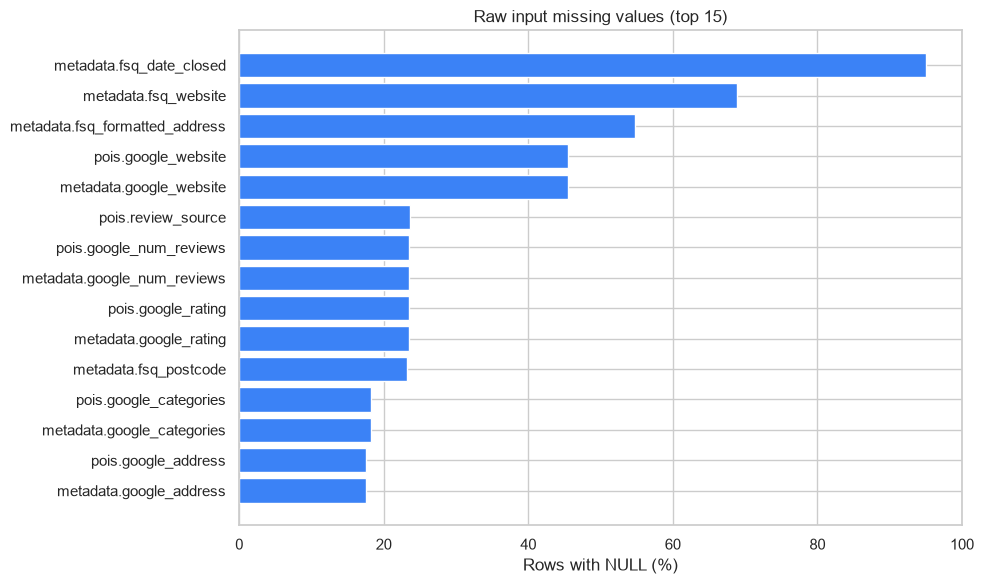

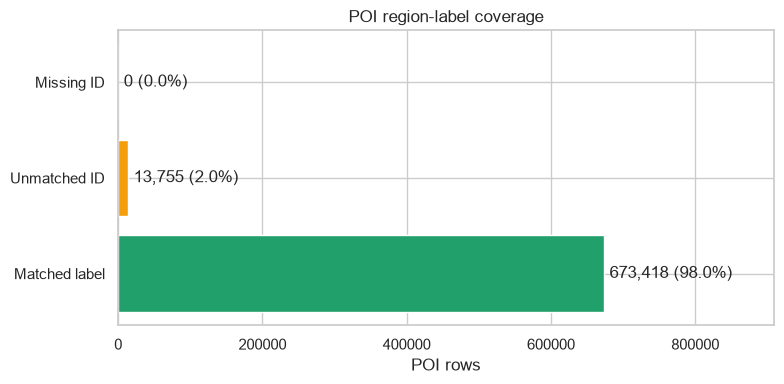

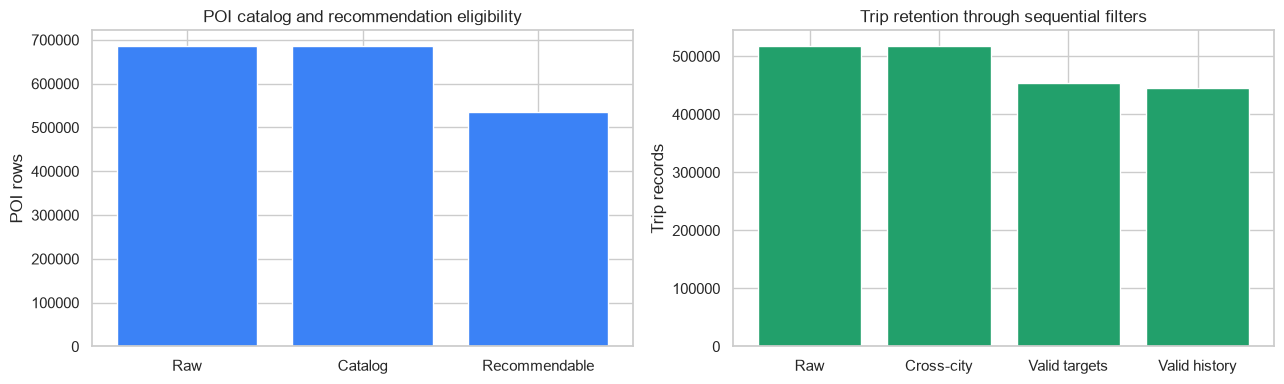

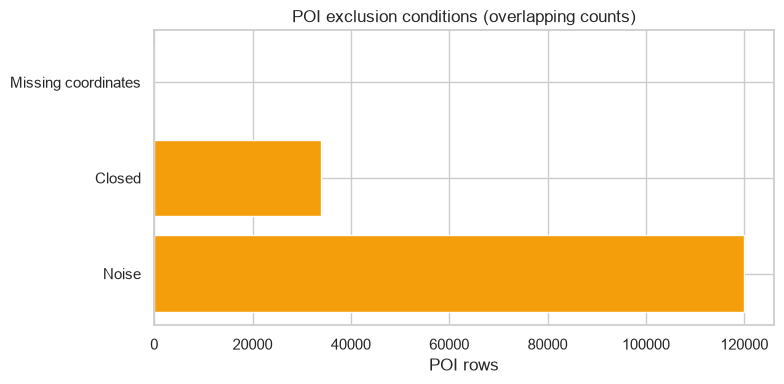

In [4]:
import json
from pathlib import Path
import duckdb
import matplotlib.pyplot as plt
from ml.config import REPORTS_DIR
from ml.data_pipeline import audit_raw_inputs, write_cleaning_summary

summary_path = REPORTS_DIR / "data_cleaning_summary.json"
if not summary_path.exists():
    with duckdb.connect() as audit_con:
        write_cleaning_summary(audit_raw_inputs(audit_con))
cleaning_report = json.loads(summary_path.read_text())
audit = cleaning_report["raw_audit"]
figure_dir = REPORTS_DIR / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
print("Summary status:", cleaning_report["status"], "| Generated:", cleaning_report["generated_at_utc"])

def save_cleaning_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(figure_dir / filename, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# Largest nonzero top-level missing-value rates (at most 15 columns).
missing = sorted([
    (f"{table}.{column}", 100 * count / info["rows"])
    for table, info in audit["tables"].items() if info["rows"]
    for column, count in info["null_counts"].items() if count
], key=lambda item: item[1], reverse=True)[:15]
fig, ax = plt.subplots(figsize=(10, 6))
if missing:
    labels, percentages = zip(*reversed(missing))
    ax.barh(labels, percentages, color="#3b82f6")
else:
    ax.text(0.5, 0.5, "No top-level null values found", ha="center", transform=ax.transAxes)
ax.set(xlabel="Rows with NULL (%)", xlim=(0, 100), title="Raw input missing values (top 15)")
save_cleaning_figure(fig, "cleaning_missing_values.png")

# Match counts use source rows, so duplicated reference keys cannot inflate them.
poi_table = audit["tables"]["pois"]
missing_regions = poi_table["missing_ids"]["locality"]
unmatched = audit["unmatched_references"]["pois_without_region_label"]
matched = poi_table["rows"] - missing_regions - unmatched
fig, ax = plt.subplots(figsize=(8, 4))
labels = ["Matched label", "Unmatched ID", "Missing ID"]
counts = [matched, unmatched, missing_regions]
bars = ax.barh(labels, counts, color=["#22a06b", "#f59e0b", "#ef4444"])
ax.bar_label(bars, labels=[f"{v:,} ({100*v/max(poi_table['rows'], 1):.1f}%)" for v in counts], padding=4)
ax.set_xlim(0, max(counts + [1]) * 1.35)
ax.set(xlabel="POI rows", title="POI region-label coverage")
save_cleaning_figure(fig, "cleaning_region_coverage.png")

cleaning = cleaning_report["cleaning"]
if cleaning is None:
    print("Retention/exclusion charts await a successful pipeline run; no cleaning results assumed.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    p = cleaning["pois"]
    axes[0].bar(["Raw", "Catalog", "Recommendable"],
                [p["input_rows"], p["catalog_rows"], p["recommendable_rows"]], color="#3b82f6")
    axes[0].set(title="POI catalog and recommendation eligibility", ylabel="POI rows")
    stages = cleaning["trip_stages"]
    axes[1].bar(["Raw", "Cross-city", "Valid targets", "Valid history"], list(stages.values()), color="#22a06b")
    axes[1].set(title="Trip retention through sequential filters", ylabel="Trip records")
    save_cleaning_figure(fig, "cleaning_retention.png")

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.barh(["Noise", "Closed", "Missing coordinates"],
            [p["noise_flagged"], p["closed_flagged"], p["missing_coordinates"]], color="#f59e0b")
    ax.set(title="POI exclusion conditions (overlapping counts)", xlabel="POI rows")
    save_cleaning_figure(fig, "cleaning_exclusion_conditions.png")


## 6. Run tests (optional)

Set `RUN_TESTS = True` to run audit and pipeline checks. Gold-data tests skip when outputs are absent and may otherwise use older files.


In [11]:
RUN_TESTS = False
if RUN_TESTS:
    import subprocess
    result = subprocess.run(
        [sys.executable, "-m", "pytest", "tests/test_ml_spine.py", "-q", "-p", "no:cacheprovider"],
        capture_output=True, text=True,
    )
    print(result.stdout)
    assert result.returncode == 0, result.stderr


## 7. Cleaning decisions

Names are now normalized and validation is strengthened. Existing exclusions, count fallbacks, and date logic remain unchanged; other items below are review decisions.

| Finding | Proposed handling | Evidence |
| --- | --- | --- |
| Missing region labels | Keep IDs; review display labels later | 13,755 POIs; none used in supplied visits |
| Missing coordinates | Keep existing recommendation exclusion | 8 POIs |
| Missing ratings/review totals | Keep ratings unknown; review zero-filling of missing counts | 161,600 missing ratings; 161,806 missing Google counts |
| Missing readable names | Keep existing name fallbacks | 3 POIs lack Google/FSQ names |
| Repeated home histories | Count each user's home activity once in global statistics | All 96,763 multi-record users have identical home lists |
| Duplicate visits | No additional event deduplication needed | No exact duplicates found |
| Broad category types | Review detailed labels and examples; avoid blanket exclusions | Attractions and offices share broad types |
| Visit/catalog mappings | Keep existing mappings | No tested mismatches |
| Corpus reviews exceed Google count | Review provenance; do not clamp automatically | 15,810 POIs |
| Non-ASCII category text | Keep text; use standardized category IDs/schema types | Category-ID/schema ASCII filter removes 0 POIs |
| Current cleaning impact | Review coverage with the team | 444,818 records; 136,958 users retained |

Cleaning outputs are validated below. Resolve missing-count policy and the open count-leakage issue during feature work.

### Feature/evaluation issue: POI count leakage

**Open — fix before trusting evaluation scores.** Raw `n_checkins` and `n_users_visited` include validation users. The raw data is valid; using these totals as model features leaks held-out behavior, even without dates.

Affected: `log_n_checkins`, `log_n_users`, and the `city_pop_pct_rank` tie-break in `ml/features/build_locality_features.py`; the popularity baseline also uses raw `n_checkins` as a tie-break. LightGBM consumes these features. The current two-tower notebook does not use these count features.

**Proposed fix during feature engineering:** compute counts from training-fold users only (`fold != val_fold`). Count home history once per user, deduplicate visit events, and use distinct users for visitor counts. Apply training-only counts to the affected tie-breaks and keep feature outputs associated with their validation fold. Raw catalog totals can remain for inspection.

**Verification:** across 276,801 fold-0 target pairs under current pipeline rules, the average validation contribution was 23.65% of raw check-in counts and 23.23% of raw visitor counts. The roughly 32% figure uses public-visit totals instead. 6.06% of pairs had no observed training-user visits in the public subset; only 2.13% had all raw counts accounted for by validation users. Public visits do not cover all activity in raw POI totals.

No fix has been applied. Score impact must be measured after correction.
